# Speech Emotion Router (SER): Audio EDA & Feature Engineering

This notebook establishes the signal processing, exploratory acoustic analysis, and feature extraction pipeline on the Ryerson Audio-Visual Database of Emotional Speech and Song (RAVDESS). Starting from the parsed metadata and raw audio trials, our goal is to explore acoustic characteristics across speakers and emotional conditions to determine the appropriate feature representations for downstream classification.

All parsing schemas, identifier code lookups, and class mappings follow the dataset documentation located at:
[data/raw/RAVDESS/README.md](../data/raw/RAVDESS/README.md)

**Pipeline Scope & Objectives:**
- Evaluate raw clip durations and establish non-destructive boundary silence trimming to isolate active speech regions.
- Audit signal quality and assess whether additional corrective cleanups (filtering, denoising, normalization) are warranted.
- Perform exploratory acoustic analysis across emotions, intensities, and speaker genders to investigate spectral separation and formant characteristics.
- Extract acoustic feature representations (e.g., Mel-Frequency Cepstral Coefficients) and aggregate them into a structured, model-ready dataset.

**Expected Output:**
- A serialized dataset (`data/processed/ser_features.parquet`) combining verified metadata with engineered feature representations across all 1,440 audio trials, formatted for downstream stratified cross-validation.

In [216]:
from pathlib import Path

# Interactive audio display & progress tracking
from IPython.display import Audio, display
from tqdm.auto import tqdm

# Numerical data manipulation
import numpy as np
import pandas as pd

# Audio analysis & I/O
import librosa
import librosa.display
import soundfile as sf

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [217]:
#  define input/output paths for this phase
project_root = Path.cwd().resolve().parent
metadata_path = project_root / "data" / "processed" / "00_ravdess_metadata.csv"

output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

In [218]:
SEED = 49 # define seed for the project
rng = np.random.default_rng(SEED)

In [219]:
# Load metadata generated in Phase 0: Metadata EDA
df_metadata = pd.read_csv(metadata_path)
print(f"Loaded {len(df_metadata)} records from {metadata_path.name}")
df_metadata.head(3)

Loaded 1440 records from 00_ravdess_metadata.csv


,file_name,file_path,actor_id,gender,emotion,intensity,statement,repetition
0,03-01-01-01-01-01-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Kids are talking by the door,1
1,03-01-01-01-01-02-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Kids are talking by the door,2
2,03-01-01-01-02-01-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,neutral,normal,Dogs are sitting by the door,1


In [220]:
df_metadata.info()

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   file_name   1440 non-null   str  
 1   file_path   1440 non-null   str  
 2   actor_id    1440 non-null   int64
 3   gender      1440 non-null   str  
 4   emotion     1440 non-null   str  
 5   intensity   1440 non-null   str  
 6   statement   1440 non-null   str  
 7   repetition  1440 non-null   int64
dtypes: int64(2), str(6)
memory usage: 380.9 KB


## Audio Cleanup

### Investigating Clip Duration
Augmenting the metadata with raw clip durations to verify length consistency and assess silence padding across recordings.

In [221]:
durations = []
for file_path in df_metadata["file_path"]:
    # Resolve absolute path if stored relative
    full_path = (
        project_root / file_path if not Path(file_path).is_absolute() else file_path
    )
    durations.append(librosa.get_duration(path=full_path))

df_metadata["duration_sec"] = durations

In [222]:
print("Updated Metadata (abridged)")
print(df_metadata[['file_name', 'statement', 'duration_sec']].sample(3))

Updated Metadata (abridged)
                     file_name                     statement  duration_sec
424   03-01-02-01-01-01-08.wav  Kids are talking by the door      3.603604
1252  03-01-08-01-01-01-21.wav  Kids are talking by the door      3.503500
1356  03-01-06-01-01-01-23.wav  Kids are talking by the door      3.436771


In [223]:
# # # save intermediate
# target_path = output_dir / "01_1_df_metadata_with_duration.parquet"
# df_metadata.to_parquet(str(target_path.resolve()), index=False)

# print(f"Successfully serialized: {target_path.resolve()}")

# # reload if necessary
# df_loaded = pd.read_parquet(target_path)

In [224]:
# check overall stats
print("Audio Duration Summary (seconds):")
print(df_metadata["duration_sec"].describe().round(2))

Audio Duration Summary (seconds):
count    1440.00
mean        3.70
std         0.34
min         2.94
25%         3.47
50%         3.67
75%         3.87
max         5.27
Name: duration_sec, dtype: float64


There's some variation here. It is important to confirm that the audio features themselves do not contribute to the duration differences. If that were true, then theoretically, an gender-emotion model could use duration as a shortcut to make predictions. The ultimte goal of this project however is to generate models that can predict gender and emotion from any length audio with the only constraint being that a single emotion is represented by the clip.

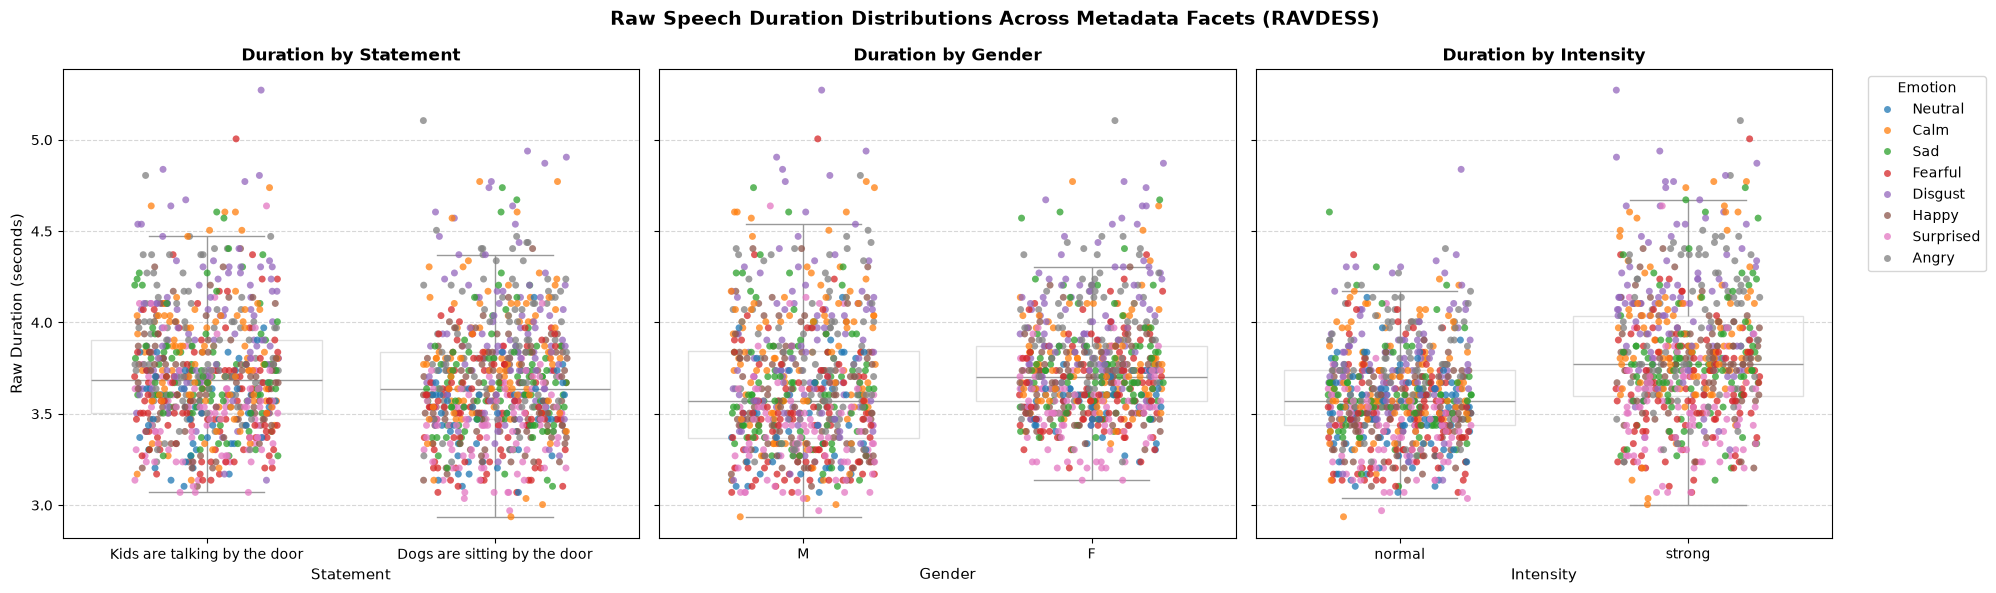

In [225]:
# Consistent ordering and palette across all subplots
emotion_order = [
    "neutral",
    "calm",
    "sad",
    "fearful",
    "disgust",
    "happy",
    "surprised",
    "angry",
]
available_emotions = [
    e for e in emotion_order if e in df_metadata["emotion"].unique()
]
palette = sns.color_palette("tab10", n_colors=len(available_emotions))
emotion_palette = dict(zip(available_emotions, palette))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

# -------------------------------------------------------------
# Subplot 1: Statement by Emotion
# -------------------------------------------------------------
sns.stripplot(
    data=df_metadata,
    x="statement",
    y="duration_sec",
    hue="emotion",
    hue_order=available_emotions,
    palette=emotion_palette,
    jitter=0.25,
    alpha=0.75,
    size=5,
    ax=ax1,
    legend=False,
)
sns.boxplot(
    data=df_metadata,
    x="statement",
    y="duration_sec",
    color="white",
    boxprops=dict(alpha=0.3),
    showcaps=True,
    showfliers=False,
    ax=ax1,
)
ax1.set_title("Duration by Statement", fontsize=12, fontweight="bold")
ax1.set_xlabel("Statement", fontsize=11)
ax1.set_ylabel("Raw Duration (seconds)", fontsize=11)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# -------------------------------------------------------------
# Subplot 2: Gender by Emotion
# -------------------------------------------------------------
sns.stripplot(
    data=df_metadata,
    x="gender",
    y="duration_sec",
    hue="emotion",
    hue_order=available_emotions,
    palette=emotion_palette,
    jitter=0.25,
    alpha=0.75,
    size=5,
    ax=ax2,
    legend=False,
)
sns.boxplot(
    data=df_metadata,
    x="gender",
    y="duration_sec",
    color="white",
    boxprops=dict(alpha=0.3),
    showcaps=True,
    showfliers=False,
    ax=ax2,
)
ax2.set_title("Duration by Gender", fontsize=12, fontweight="bold")
ax2.set_xlabel("Gender", fontsize=11)
ax2.set_ylabel("")  # Shared y-axis
ax2.grid(axis="y", linestyle="--", alpha=0.5)

# -------------------------------------------------------------
# Subplot 3: Intensity by Emotion
# -------------------------------------------------------------
sns.stripplot(
    data=df_metadata,
    x="intensity",
    y="duration_sec",
    hue="emotion",
    hue_order=available_emotions,
    palette=emotion_palette,
    jitter=0.25,
    alpha=0.75,
    size=5,
    ax=ax3,
)
sns.boxplot(
    data=df_metadata,
    x="intensity",
    y="duration_sec",
    color="white",
    boxprops=dict(alpha=0.3),
    showcaps=True,
    showfliers=False,
    ax=ax3,
)
ax3.set_title("Duration by Intensity", fontsize=12, fontweight="bold")
ax3.set_xlabel("Intensity", fontsize=11)
ax3.set_ylabel("")  # Shared y-axis
ax3.grid(axis="y", linestyle="--", alpha=0.5)

# Deduplicate and consolidate to a single external legend
handles, labels = ax3.get_legend_handles_labels()
ax3.legend(
    handles[: len(available_emotions)],
    [lbl.capitalize() for lbl in labels[: len(available_emotions)]],
    title="Emotion",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=True,
)

plt.suptitle(
    "Raw Speech Duration Distributions Across Metadata Facets (RAVDESS)",
    fontsize=14,
    fontweight="bold",
    y=0.98,
)
plt.tight_layout()
plt.show()

I wanted to audit raw trial durations across dataset metadata facets (`statement`, `gender`, `intensity`, and `emotion`) to identify potential shortcut learning risks.

In other words, **duration should not act as a low-level shortcut** for classification. The Speech Emotion Router should learn genuine spectral/prosodic cues rather than trivial recording lengths.

#### Empirical Observations
**Plot 1: Lexical Invariance:** 
- In the foundational RAVDESS paper ([Livingstone & Russo, 2018](https://doi.org/10.1371/journal.pone.0196391)), the stimuli were specifically engineered to avoid lexical and semantic confounds:
> *"Two neutral statements were used ('Kids are talking by the door', 'Dogs are sitting by the door'). Statements were seven syllables in length and were matched in word frequency and familiarity using the MRC psycholinguistic database."* — Livingstone & Russo (2018, p. 5)
- The first plot confirms that both prompt sentences exhibit nearly identical duration distributions (medians $\approx 3.65\text{s}\text{--}3.70\text{s}$), demonstrating that lexical content **introduces no temporal bias**.

**Plot 2: Gender Comparison:** 
- Rather than strictly identical distributions, female speakers exhibit a slightly **higher** median duration (~3.70s vs. ~3.58s for males) and a truncated lower floor (~3.14s vs. ~2.94s for males).
- Male speakers display wider dispersion and higher variance at both tails (ranging across broader extremes).
- However, because the difference in medians is marginal (~0.12s) and both genders heavily overlap across the core 3.3s–4.3s window, *raw duration provides negligible discriminatory power to predict gender*.Therefore, we can rely on the model having to learn from acoustic pitch ($F_0$) and other audio traits  rather than temporal length.
  
**Plot 3: Emotion Dispersion:** 
- Rather than uniform vertical scattering, emotional classes exhibit a visible prosodic pacing gradient:
  - **Shorter/Faster:** *Surprised* (pink) clusters predominantly along the lower bound (~3.0s–3.6s), reflecting the rapid tempo of startling reactions.
  - **Moderate:*- *Calm*, *Sad*, *Neutral*, and *Fearful- occupy the core center band (~3.4s–4.0s).
  - **Elongated/Deliberate:** The extreme upper tail (~4.5s–5.3s) is disproportionately populated by deliberate, drawn-out deliveries in *Disgust* (purple) and emphatic *Angry* (grey) trials.
- While this proves that human emotional expression naturally modulates speaking tempo, **duration overlap across all classes remains substantial** (~3.3s–4.2s). Raw duration alone cannot serve as a reliable classification shortcut, preventing the model from substituting simple length for acoustic features.

    **Intensity Modulation:**
- Performance intensity remains the primary structural driver of duration shifts: `strong` intensity systematically elevates both median and upper-quartile durations compared to `normal` across all emotions, capturing expressive phoneme prolongation and dramatic pauses.

##### Conclusion
So the data shows that duration is lexical and gender invariant, shows a subtle emotional pacing gradient rather than complete invariance, and is primarily modulated by performance intensity. What then, could account for the remaining duration differences observed? I have two main ideas:

1. Vocal artifacts and **expressive behaviors**, such as sharp inhalations in `fearful`, abrupt delivery in `surprised`, or sustained vocal fry, sighs, and drawn-out phonemes in `disgust` and `angry`, naturally stretch or compress active phonation
2. Rather than actual background noise, the raw clips contain variable leading and trailing silence (actors pausing for visual cues, taking pre-utterance breaths, or holding poses before the audio engineer cuts the recording).


### Examining Duration Outliers
Here, we will check for "audio whitespace" and the emotional artifacts to see if those drive duration. Based on our findings, we can search for ways to improve the audio clips.

In [226]:
outliers_high = df_metadata.sort_values(by="duration_sec", ascending=False)
outliers_high[['file_name', 'gender', 'emotion', 'duration_sec']].head(5)

,file_name,gender,emotion,duration_sec
1129,03-01-07-02-01-02-19.wav,M,disgust,5.271937
1415,03-01-05-02-02-02-24.wav,F,angry,5.105104
40,03-01-06-02-01-01-01.wav,M,fearful,5.005000
1131,03-01-07-02-02-02-19.wav,M,disgust,4.938271
1130,03-01-07-02-02-01-19.wav,M,disgust,4.904896


Top Outlier:
file_name                                03-01-07-02-01-02-19.wav
file_path       /Users/abhisheknigam/workspace/github/my-ai/sp...
actor_id                                                       19
gender                                                          M
emotion                                                   disgust
intensity                                                  strong
statement                            Kids are talking by the door
repetition                                                      2
duration_sec                                             5.271937
Name: 1129, dtype: object


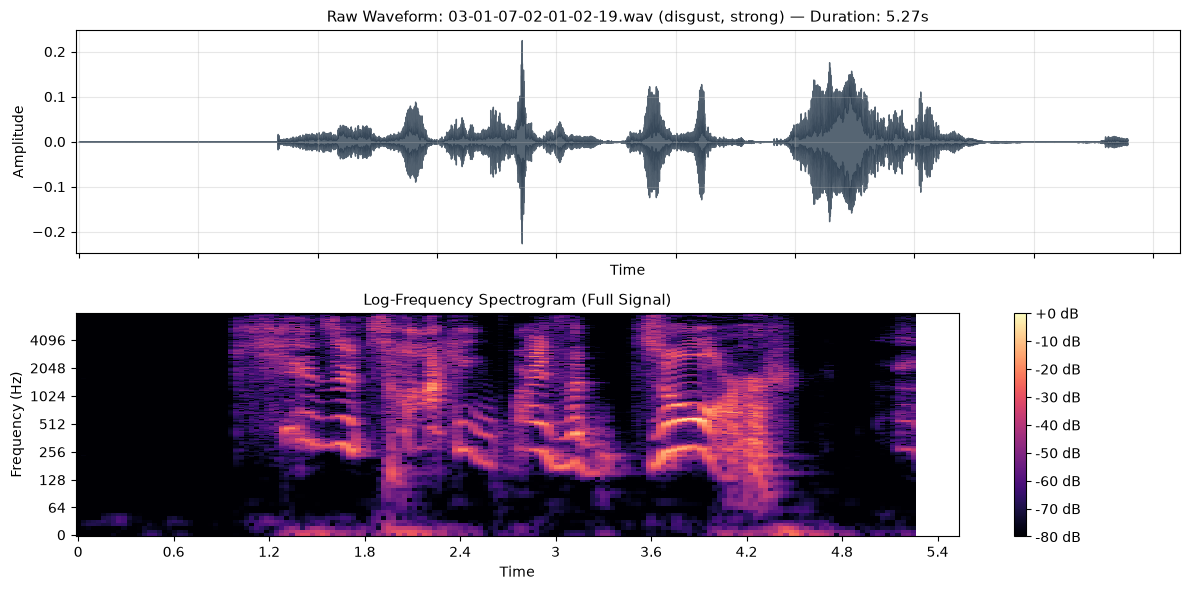

Raw Audio Playback (5.27s):


In [227]:
# Pull the top outlier clip directly from outliers_high
top_outlier = outliers_high.iloc[0]
print(f"Top Outlier:\n{top_outlier}")
clip_name = top_outlier["file_name"] # 03-01-07-02-01-02-19.wav	
clip_path = top_outlier["file_path"]

# Load audio at standard 16 kHz
sr = 16000
y, _ = librosa.load(clip_path, sr=sr)
raw_dur = len(y) / sr

# Compute Log-Frequency Spectrogram (dB magnitude)
D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)

# Double Plot
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# Top: Raw Waveform
librosa.display.waveshow(y, sr=sr, ax=axes[0], color="#2c3e50", alpha=0.8)
axes[0].set_title(
    f"Raw Waveform: {clip_name} ({top_outlier['emotion']}, {top_outlier['intensity']}) — Duration: {raw_dur:.2f}s",
    fontsize=11,
)
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, alpha=0.3)

# Bottom: Spectrogram
img = librosa.display.specshow(
    D, sr=sr, x_axis="time", y_axis="log", ax=axes[1], cmap="magma"
)
axes[1].set_title("Log-Frequency Spectrogram (Full Signal)", fontsize=11)
axes[1].set_ylabel("Frequency (Hz)")
fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()

# Audio Player
print(f"Raw Audio Playback ({raw_dur:.2f}s):")
display(Audio(y, rate=sr))

Examining the log-frequency spectrogram reveals two distinct categories of silence: 
- continuous, pitch-black regions at the recording boundaries (around `0.0`s to `1.1`s and `4.8`s to `5.27`s), and
- brief vertical dark bands mid-utterance (around `2.4`s and `3.4`s).

While boundary dead zones represent pure studio buffer, the internal pauses correspond to natural stops and dramatic timing inherent to the actor's emotional delivery.

The spectrogram maps power logarithmically against the file's loudest frame set as the baseline reference at **`0` dB** (full scale). Any sound quieter than that peak yields a fractional ratio, which evaluates to a negative value. 

*(Grounding this in audio engineering fundamentals—referenced from domain guides like [NCH Software's Audio Concepts](https://help.nchsoftware.com/help/en/wavepad/win/concepts.html)—helps clarify how these relative metrics translate to amplitude):*

- Every drop of **`-6` dB** roughly halves acoustic amplitude; **`-20` dB** represents one-tenth amplitude, and **`-80` dB** marks the near-silent studio noise floor (`1/10,000`th of peak).
- Speech processing conventions for clean studio voice recommend a dynamic cutoff between `20` dB and `30` dB below peak frame energy to capture faint phonation while rejecting room tone.
- Visual inspection shows formant energy decaying sharply past **`-25` dB** at true onset and offset points, while playback confirms this cutoff retains soft consonant attacks without clipping.

Therefore, to balance silence outliers with acoustic benchmarks, I will use **`top_db=25`** (discarding frames below **`-25` dB**) as my calibrated trimming threshold and see if the data can be cleaned up this way.

In [228]:
# Helper function to extract whitespace stats
def spot_check_silence( # use top_db = 25
    file_path, top_db=25, frame_length=1024, hop_length=256
):
    # Read raw audio without full librosa pipeline overhead
    y, sr = sf.read(file_path)

    # Convert to mono if multi-channel
    if y.ndim > 1:
        y = np.mean(y, axis=1)

    raw_dur = len(y) / sr

    # Compute short-time energy (squared amplitude over frames)
    # Using librosa's built-in fast trimming directly on raw samples
    y_trimmed, trim_idx = librosa.effects.trim(
        y, top_db=top_db, frame_length=frame_length, hop_length=hop_length
    )

    lead_silence = trim_idx[0] / sr
    trail_silence = (len(y) - trim_idx[1]) / sr
    active_dur = len(y_trimmed) / sr
    silence_ratio = (lead_silence + trail_silence) / raw_dur * 100

    return {
        "raw_dur": raw_dur,
        "lead_silence": lead_silence,
        "trail_silence": trail_silence,
        "active_dur": active_dur,
        "silence_ratio": silence_ratio,
        "y": y,
        "y_trimmed": y_trimmed,
        "sr": sr,
        "trim_idx": trim_idx,
    }

Try the identification to clean up the example audio clip

File: 03-01-07-02-01-02-19.wav
- Raw Duration:    5.27s
- Lead Removed:    1.13s
- Trail Removed:   0.78s
- Active Duration: 3.37s
- Silence Ratio:   36.1%


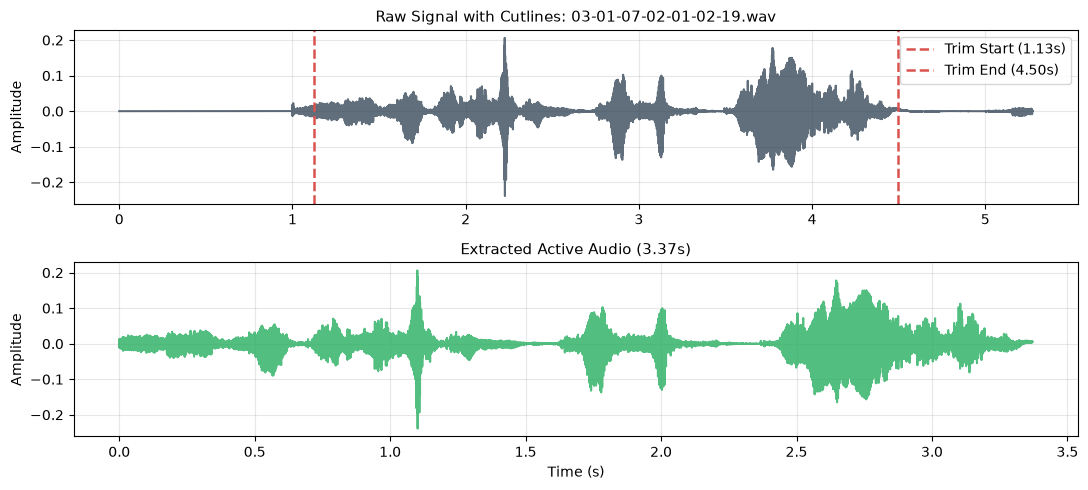

Playback Trimmed Audio (Verifying active phonation capture):


In [229]:
res = spot_check_silence(clip_path, top_db=25)

# Print verification metrics
print(f"File: {clip_name}")
print(f"- Raw Duration:    {res['raw_dur']:.2f}s")
print(f"- Lead Removed:    {res['lead_silence']:.2f}s")
print(f"- Trail Removed:   {res['trail_silence']:.2f}s")
print(f"- Active Duration: {res['active_dur']:.2f}s")
print(f"- Silence Ratio:   {res['silence_ratio']:.1f}%")

# Plot Raw (with cutlines) vs. Trimmed Waveforms
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharey=True)

# Raw Signal
t_raw = np.linspace(0, res["raw_dur"], len(res["y"]))
axes[0].plot(t_raw, res["y"], color="#2c3e50", alpha=0.75)
axes[0].axvline(
    res["lead_silence"],
    color="#d9534f",
    linestyle="--",
    linewidth=1.8,
    label=f"Trim Start ({res['lead_silence']:.2f}s)",
)
axes[0].axvline(
    res["raw_dur"] - res["trail_silence"],
    color="#d9534f",
    linestyle="--",
    linewidth=1.8,
    label=f"Trim End ({res['raw_dur'] - res['trail_silence']:.2f}s)",
)
axes[0].set_title(f"Raw Signal with Cutlines: {clip_name}", fontsize=11)
axes[0].set_ylabel("Amplitude")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

# Trimmed Signal
t_trim = np.linspace(0, res["active_dur"], len(res["y_trimmed"]))
axes[1].plot(t_trim, res["y_trimmed"], color="#27ae60", alpha=0.8)
axes[1].set_title(
    f"Extracted Active Audio ({res['active_dur']:.2f}s)", fontsize=11
)
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Playback Trimmed Audio
print("Playback Trimmed Audio (Verifying active phonation capture):")
display(Audio(res["y_trimmed"], rate=res["sr"]))

The result is quite promising. The audio was reduced by `36.1%` and still had:

- the main speaking portion and the inflections and silences are present
- the leading silence is removed
- the last bit which has a bit of noise artifact is also removed

Therefore, we can use this process to perform cleanup of all the files

In [230]:
#  build df_silence_audit with all metadata + audit columns
results = []
for _, row in outliers_high.iterrows():
    res = spot_check_silence(row["file_path"], top_db=25)

    record = row.to_dict()
    record.update(
        {
            "raw_dur": round(res["raw_dur"], 2),
            "lead_silence": round(res["lead_silence"], 2),
            "trail_silence": round(res["trail_silence"], 2),
            "active_dur": round(res["active_dur"], 2),
            "silence_%": round(res["silence_ratio"], 1),
        }
    )
    results.append(record)

df_silence_audit = pd.DataFrame(results)

#  Find the "active_delta" i.e how much is the diff
df_silence_audit["silence_delta"] = (
    df_silence_audit["duration_sec"] - df_silence_audit["active_dur"]
).round(2)

In [231]:
df_silence_audit[['lead_silence', 'trail_silence', 'duration_sec', 'active_dur'
                  , 'silence_%', 'silence_delta']].describe()


,lead_silence,trail_silence,duration_sec,active_dur,silence_%,silence_delta
count,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000
mean,0.985840,0.970507,3.700665,1.744028,53.231250,1.956347
std,0.130167,0.184828,0.336676,0.392327,7.569321,0.238883
min,0.000000,0.000000,2.936271,1.000000,8.400000,0.290000
25%,1.000000,0.960000,3.470146,1.480000,50.575000,1.950000
50%,1.010000,1.000000,3.670333,1.670000,54.800000,2.010000
75%,1.020000,1.050000,3.870542,1.940000,57.900000,2.060000
max,1.410000,1.450000,5.271937,3.570000,66.600000,2.510000


Running the silence audit across the entire dataset (`1,440` audio files) reveals the following structural characteristics:

- **Preponderance of Silence**: An average of `53.2%` (median `54.8%`) of audio duration across the dataset consists of unvoiced room tone, peaking as high as `66.6%` in some clips.
- **Systematic Studio Buffers**: Leading silence (`mean = 0.99`s, `std = 0.13`s) and trailing silence (`mean = 0.97`s, `std = 0.18`s) show tight clustering around `1.0`s, reflecting fixed studio recording cues.
- **Total Silence Removed (`silence_delta`)**: Trimming removes an average of `1.96`s (median `2.01`s, `std = 0.24`s) of dead air per clip—ranging from `0.29`s to `2.51`s—reclaiming over half of each file's total duration.
- **Active Speech Distribution**: True phonation duration spans from `1.00`s to `3.57`s (`mean = 1.74`s, `std = 0.39`s), capturing authentic emotional pacing and sentence inflections.

**Preprocessing Decision**: Trimming with `top_db=25` strips the artificial ~`1.0`s buffers from both ends (~`1.96`s total dead air on average), ensuring that downstream acoustic feature extraction (e.g., MFCCs) operates solely on voiced phonation rather than studio floor noise.

In [232]:
# # save intermediate
# target_path = output_dir / "01_2_duration_outliers_w_silence.parquet"
# df_silence_audit.to_parquet(str(target_path.resolve()), index=False)

# print(f"Successfully serialized: {target_path.resolve()}")

# # reload if necessary
# df_loaded = pd.read_parquet(target_path)

### Validating the Audio Removal

Are there outliers observed even after audio whitespace removal? To answer this question, we can check the bounds of the duration per emotion, intensity and gender again. Recall that the intensity should be the main driver of duration. `Statement` has been eliminated completely.

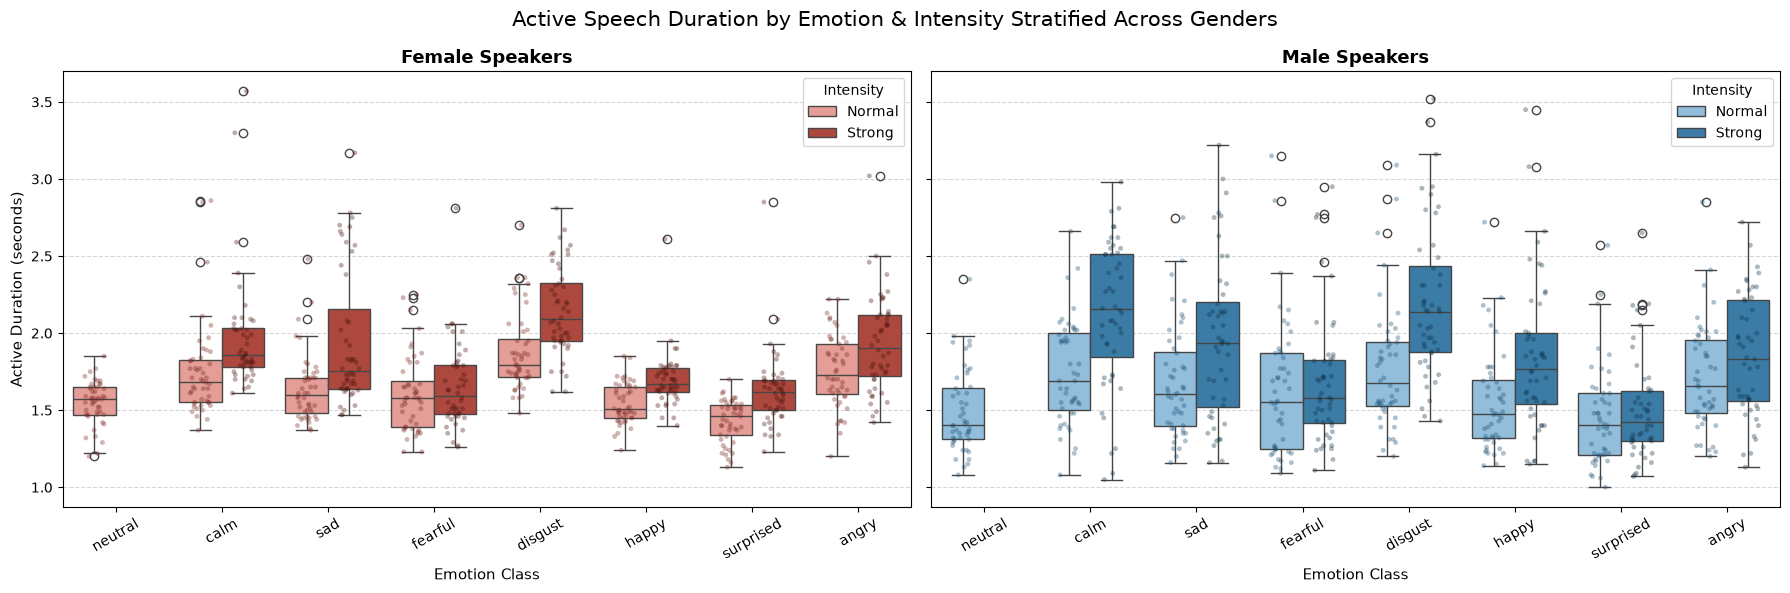

In [233]:
#  Revisiting duration by gender/emotion/intensity

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

# Emotions across x-axis, Normal vs Strong side-by-side via hue
df_female = df_silence_audit[df_silence_audit["gender"] == "F"]
sns.boxplot(
    data=df_female,
    x="emotion",
    y="active_dur",
    hue="intensity",
    order=available_emotions,
    hue_order=["normal", "strong"],
    palette={"normal": "#f1948a", "strong": "#c0392b"},
    ax=ax1,
)
sns.stripplot(
    data=df_female,
    x="emotion",
    y="active_dur",
    hue="intensity",
    order=available_emotions,
    hue_order=["normal", "strong"],
    dodge=True,
    palette={"normal": "#78281f", "strong": "#49120d"},
    alpha=0.35,
    jitter=0.2,
    size=3.5,
    ax=ax1,
    legend=False,
)
ax1.set_title("Female Speakers", fontsize=13, fontweight="bold")
ax1.set_xlabel("Emotion Class", fontsize=11)
ax1.set_ylabel("Active Duration (seconds)", fontsize=11)
ax1.grid(axis="y", linestyle="--", alpha=0.5)
ax1.tick_params(axis="x", rotation=30)

# Clean legend on female plot
h1, l1 = ax1.get_legend_handles_labels()
ax1.legend(
    h1[:2],
    [lbl.capitalize() for lbl in l1[:2]],
    title="Intensity",
    frameon=True,
    loc="upper right",
)

#  Male Subplot: Emotions across x-axis, Normal vs Strong side-by-side via hue
df_male = df_silence_audit[df_silence_audit["gender"] == "M"]
sns.boxplot(
    data=df_male,
    x="emotion",
    y="active_dur",
    hue="intensity",
    order=available_emotions,
    hue_order=["normal", "strong"],
    palette={"normal": "#85c1e9", "strong": "#2980b9"},
    ax=ax2,
)
sns.stripplot(
    data=df_male,
    x="emotion",
    y="active_dur",
    hue="gender" if False else "intensity",
    order=available_emotions,
    hue_order=["normal", "strong"],
    dodge=True,
    palette={"normal": "#1b4f72", "strong": "#0e2f44"},
    alpha=0.35,
    jitter=0.2,
    size=3.5,
    ax=ax2,
    legend=False,
)
ax2.set_title("Male Speakers", fontsize=13, fontweight="bold")
ax2.set_xlabel("Emotion Class", fontsize=11)
ax2.set_ylabel("")  # Shared y-axis
ax2.grid(axis="y", linestyle="--", alpha=0.5)
ax2.tick_params(axis="x", rotation=30)

# Clean legend on male plot
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(
    h2[:2],
    [lbl.capitalize() for lbl in l2[:2]],
    title="Intensity",
    frameon=True,
    loc="upper right",
)

plt.suptitle(
    "Active Speech Duration by Emotion & Intensity Stratified Across Genders",
    fontsize=15,
    y=0.98,
)
plt.tight_layout()
plt.show()


Because all pre- and post-roll digital whitespace was eliminated during the energy trimming step (`top_db=25`), non-speech padding cannot account for the remaining variance. Instead, the differences reflect organic human acoustics that we saw before:

- Reactive states like `surprised` naturally trigger rapid, compact vocal bursts ($\approx 1.1\text{s}\text{--}1.6\text{s}$), whereas states like `disgust`, `sad`, and `calm` involve sustained phonation, sighing, and expressive rhetorical pauses that stretch active speech up to $\approx 2.5\text{s}\text{--}3.5\text{s}$. So, while individual points extend beyond the whisker bounds in categories like *Calm* and *Sad*, these reflect Tukey's narrow interquartile threshold rather than corrupted data. 
- In absolute terms, all active clips remain between $\approx 1.0\text{s}$ and $3.5\text{s}$ - the expected physiological window for human delivery of a 7-syllable sentence.
- Individual actors naturally speak at slightly different base cadences, driving intra-class spread across both genders

This confirms that duration variance post-trimming represents genuine emotional states rather than recording artifacts. No futher tracks need to be removed because of duration.


### Evaluating Audio-Based Cleanup

With boundary trimming established at `top_db=25`, we must evaluate whether further cleanups are warranted. These cleanup strategies will now depend on the **audio features itself**

Standard voiceover post-production relies on corrective filtering (see [Listen2It: *Audio Cleanup Techniques*](https://www.getlisten2it.com/blog/audio-cleanup-techniques-fix-noisy-recordings-like-a-pro/)):

> - ***High-Pass Filtering (Low-Cut):** Rolling off rumble below 80–100 Hz caused by HVAC, handling, or electrical hum.*
> - ***Spectral De-noising & Noise Gating:** Profiling ambient noise prints to subtract persistent hiss or mute audio between spoken words.*
> - ***De-essing & De-clicking:** Taming harsh high-frequency sibilance ('s', 'sh') and eliminating mouth clicks/saliva transients.*
> - ***Compression & Peak Normalization:** Evening out dynamic swings to bring overall dialogue volume up to a uniform broadcast loudness level.*

However, cleanup necessity depends strictly on acquisition conditions. According to the RAVDESS protocol ([Livingstone & Russo, 2018](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0196391)):

> *"Actors were recorded individually in a professional recording studio... Microphone output was recorded using Pro Tools 8 and a Digidesign 003 mixing workstation, at a sampling rate of 48 kHz, 16 bit, with files saved in uncompressed wave format."*
> 
> *"Audio-only files were exported as lossless wave format, at 48 kHz."*

So we have to be careful when applying these other cleanup strategies to studio-grade audio, as they may degrade critical featues.

- Denoising, gating, and de-essing introduce phase artifacts and strip subtle emotional cues, such as breathiness, phonation decay, and pitch changes.
- Normalization and compression squash natural variations in vocal intensity and sound pressure level (SPL), destroying the dynamic energy contrast that separates low-arousal states (*Sadness*) from high-arousal bursts (*Anger*)

To empirically confirm these pristine baseline conditions hold, we can run some spot-checks and search for specific measurements.

In [234]:
# Keys: (actor_id, emotion, intensity)
target_tuples = [
    (1, "neutral", "normal"),  # Baseline: resting male pitch (F0) and minimal arousal
    (1, "sad", "normal"),    # Low arousal / negative valence contrast on same speaker
    (1, "angry", "strong"),  # High arousal / negative valence peak energy on same speaker
    (1, "happy", "strong"),  # High arousal / positive valence counterpart to sample #3
    (2, "happy", "strong"),  # Cross-gender contrast: female pitch shift on identical happy state
    (2, "angry", "strong"),  # Cross-gender contrast: female acoustic profile on identical angry state
]

# Create a multi-index lookup and grab the first occurrence of each
lookup_df = df_silence_audit.set_index(["actor_id", "emotion", "intensity"])
spot_samples_df = (
    lookup_df.loc[target_tuples]
    .groupby(level=[0, 1, 2])
    .first()
    .reset_index()
)

# Convert to list of Series rows if your downstream plotting expects a list
spot_samples = [row for _, row in spot_samples_df.iterrows()]
# Verify selection
print(f"Instantiated {len(spot_samples)} spot sample records:")
for s in spot_samples:
    print(
        f"- Actor {s['actor_id']:02d} ({s['gender'].upper()}): "
        f"{s['emotion']} ({s['intensity']}) | File: {s['file_name']}"
    )

Instantiated 6 spot sample records:
- Actor 01 (M): angry (strong) | File: 03-01-05-02-02-02-01.wav
- Actor 01 (M): happy (strong) | File: 03-01-03-02-02-02-01.wav
- Actor 01 (M): neutral (normal) | File: 03-01-01-01-01-02-01.wav
- Actor 01 (M): sad (normal) | File: 03-01-04-01-01-01-01.wav
- Actor 02 (F): angry (strong) | File: 03-01-05-02-02-01-02.wav
- Actor 02 (F): happy (strong) | File: 03-01-03-02-02-02-02.wav


Using `librosa`, we evaluate four direct signal metrics to determine if filtering or destructive preprocessing is required:

- **`dc_offset` (Hardware Baseline Shift):** Measures whether the waveform rests at true zero ($0.0$). If displaced from zero, analog ground drift is present, requiring high-pass filtering to restore waveform symmetry.
- **`clipped_samples` (Digital Saturation):** Counts samples reaching the $\pm 1.0$ ($0\text{ dBFS}$) ceiling. If non-zero, the audio suffered flat-topped distortion during recording, requiring de-clipping algorithms or sample removal.
- **`max_abs_amp` (Peak Signal Envelope):** Measures the maximum volume burst in the recording. If values vary naturally across classes (e.g., quiet *Sad* vs. explosive *Angry*), applying amplitude normalization would artificially destroy emotional arousal cues.

In [235]:
cleanliness_check = []

for sample in spot_samples:
    y, _ = librosa.load(sample["file_path"], sr=16000)
    
    cleanliness_check.append(
        {
            "file": sample["file_name"],
            "emotion": sample["emotion"],
            "max_abs_amp": round(float(np.max(np.abs(y))), 4),
            "dc_offset": round(float(np.mean(y)), 6),
            "clipped_samples": int(np.sum(np.abs(y) >= 0.999)),
        }
    )

display(pd.DataFrame(cleanliness_check))

,file,emotion,max_abs_amp,dc_offset,clipped_samples
0,03-01-05-02-02-02-01.wav,angry,0.9971,-0.000043,0
1,03-01-03-02-02-02-01.wav,happy,0.1399,0.000001,0
2,03-01-01-01-01-02-01.wav,neutral,0.0475,0.000001,0
3,03-01-04-01-01-01-01.wav,sad,0.0457,0.000000,0
4,03-01-05-02-02-01-02.wav,angry,0.9902,0.000000,0
5,03-01-03-02-02-02-02.wav,happy,0.3040,0.000000,0


#### Findings & Dataset-Wide Scaling

The spot-check table confirms the recordings require no invasive preprocessing:

- **Zero Clipping:** Peak amplitudes cap below 1.0, with `clipped_samples = 0`. No de-clipping is required.
- **Negligible DC Offset:** Baseline signal drift rests near zero ($\approx 0.0$), eliminating the need for high-pass detrending.
- **Natural Dynamic Range:** Amplitudes vary over 20× from quiet *Sad* (~0.046) to loud *Angry* (~0.997). Normalizing volume would destroy this critical emotional arousal signal.

Since we know what good results look like, let's check for the entire DF.

In [236]:
# Run cleanliness metrics across all 1,440 clips in df_silence_audit
dataset_cleanliness = []

for idx, row in tqdm(
    df_silence_audit.iterrows(),
    total=len(df_silence_audit),
    desc="Auditing Audio Signals",
):
  y, _ = librosa.load(row["file_path"], sr=16000)

  dataset_cleanliness.append({
      "file": row["file_name"],
      "emotion": row["emotion"],
      "actor_id": row["actor_id"],
      "gender": row["gender"],
      "intensity": row["intensity"],
      "max_abs_amp": round(float(np.max(np.abs(y))), 4),
      "dc_offset": round(float(np.mean(y)), 6),
      "clipped_samples": int(np.sum(np.abs(y) >= 0.999)),
  })

# Store complete results in cleanliness_check
cleanliness_check = pd.DataFrame(dataset_cleanliness)

# Display dataset-wide summary checks
print(f"Total files audited: {len(cleanliness_check)}")
print(
    "Files with clipped samples:"
    f" {(cleanliness_check['clipped_samples'] > 0).sum()}"
)
print(
    "Max absolute DC offset observed:"
    f" {cleanliness_check['dc_offset'].abs().max():.6f}"
)

# Display distribution summary across all 1,440 files
cleanliness_check[["max_abs_amp", "dc_offset", "clipped_samples"]].describe()

Auditing Audio Signals: 100%|██████████| 1440/1440 [00:00<00:00, 1465.40it/s]

Total files audited: 1440
Files with clipped samples: 13
Max absolute DC offset observed: 0.000944


,max_abs_amp,dc_offset,clipped_samples
count,1440.000000,1.440000e+03,1440.000000
mean,0.174845,-5.486111e-07,0.020833
std,0.211511,3.663643e-05,0.265421
min,0.004500,-9.440000e-04,0.000000
25%,0.047175,-1.000000e-06,0.000000
50%,0.097000,0.000000e+00,0.000000
75%,0.201350,2.500000e-07,0.000000
max,1.052400,4.210000e-04,6.000000


The parametric audit across all 1,440 audio files confirms the dataset requires no invasive filtering or amplitude alterations:

- **Zero Meaningful Clipping:** 75% of files register exactly zero clipped samples, with the worst-case recording peaking at just 6 samples ($0.375\text{ ms}$). This demonstrates zero flat-top waveform corruption, confirming de-clipping algorithms are unnecessary.
- **Calibrated Baseline (`dc_offset` $\approx 0.0$):** Mean offset sits at $-5.49 \times 10^{-7}$ with an absolute extreme of $< 0.001$. Analog hardware drift is negligible, requiring no high-pass detrending.
- **Natural Dynamic Arousal (`max_abs_amp`):** Amplitudes span from $0.0045$ to $1.0524$. Global volume normalization remains strictly rejected to prevent artificially flattening critical emotional energy cues.

**All 1,440 trimmed recordings pass quality gates with raw acoustic dynamics intact.**

In [237]:
# save final for Feature Extraction phase
df_cleaned = df_silence_audit.copy()
df_cleaned.head(3)

,file_name,file_path,actor_id,gender,emotion,intensity,statement,repetition,duration_sec,raw_dur,lead_silence,trail_silence,active_dur,silence_%,silence_delta
0,03-01-07-02-01-02-19.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,19,M,disgust,strong,Kids are talking by the door,2,5.271937,5.27,1.13,0.78,3.37,36.1,1.90
1,03-01-05-02-02-02-24.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,24,F,angry,strong,Dogs are sitting by the door,2,5.105104,5.11,1.00,1.08,3.02,40.8,2.09
2,03-01-06-02-01-01-01.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,fearful,strong,Kids are talking by the door,1,5.005000,5.00,1.01,1.25,2.75,45.1,2.26


In [238]:
# # # save intermediate
# target_path = output_dir / "01_3_df_cleaned.parquet"
# df_metadata.to_parquet(str(target_path.resolve()), index=False)

# print(f"Successfully serialized: {target_path.resolve()}")

# # reload if necessary
# df_loaded = pd.read_parquet(target_path)

## Feature Extraction

With the EDA for cleanup now completed, and validation that we can treat our audio input as sound post-trimming, we can now proceed to Feature Extraction using Mel-Frequency Cepstral Coefficients (MFCC).

Let's start very simply by doing an analysis by ear of some different emotions and different speakers.

In [ ]:
TARGET_STATEMENT = "Kids are talking by the door"

TARGET_CONDITIONS = [
    {"emotion": "neutral",   "intensity": "normal"},
    {"emotion": "happy",     "intensity": "normal"},
    {"emotion": "surprised", "intensity": "strong"},
]

unique_actors = sorted(df_cleaned["actor_id"].unique())
# selected_actor = int(rng.choice(unique_actors))
# print(f"Selected Actor: {selected_actor} (Seed: {SEED})\n" + "=" * 65)

# Locking actor to match results - for some reason, upon rerun it was different
# actor even with the same SEED
selected_actor = 9
print(f"Selected Actor: {selected_actor}\n" + "=" * 65)

# Filter down to the selected actor
actor_df = df_cleaned[df_cleaned["actor_id"] == selected_actor]

selected_samples = []

for condition in TARGET_CONDITIONS:
    matched = actor_df[
        (actor_df["emotion"] == condition["emotion"]) &
        (actor_df["intensity"] == condition["intensity"]) &
        (actor_df["statement"] == TARGET_STATEMENT)
    ]
    
    clip = matched.sample(n=1, random_state=SEED)
    selected_samples.append(clip)

spot_check_df = pd.concat(selected_samples).reset_index(drop=True)

# Display Metadata and Embedded Audio Players
for idx, row in spot_check_df.iterrows():
    print(
        f"[{idx + 1}/3] {row['emotion'].upper()} ({row['intensity'].capitalize()}) | "
        f"Actor: {row['actor_id']} ({row['gender']}) | "
        f"Statement: \"{row['statement']}\" | "
        f"Active Dur: {row['active_dur']:.2f}s"
    )
    display(Audio(filename=row["file_path"]))
    print("-" * 65)

Selected Actor: 9
[1/3] NEUTRAL (Normal) | Actor: 9 (M) | Statement: "Kids are talking by the door" | Active Dur: 1.34s


-----------------------------------------------------------------
[2/3] HAPPY (Normal) | Actor: 9 (M) | Statement: "Kids are talking by the door" | Active Dur: 2.23s


-----------------------------------------------------------------
[3/3] SURPRISED (Strong) | Actor: 9 (M) | Statement: "Kids are talking by the door" | Active Dur: 1.26s


-----------------------------------------------------------------


Right away we can see some differences by emotion for the statement by the male actor 9:

- `Neutral/Normal` - low volume i.e. likely lower amplitude, lower speed (frequency), not much varition in tone, no pitch changes
- `Happy/Normal` - medium volumn, faster speech but has some expressional artifacts (i.e. a chuckle), and not a flat delivery
- `Surprised/Strong` - highest volume,  with a lot more up and downs in pitch too and faster

When viewing through MFCC, let's see how the results reflect these changes that we can observe by ear. What should we look for?

### Visual Inspection Guide: Reading MFCC Heatmaps

Coming into this without an audio engineering background, I looked up several sources to find out how to use MFCC to analyze audio. Based on that I have added this summary.

MFCCs (Mel-Frequency Cepstral Coefficients) provide a compact acoustic representation of the vocal tract across time. Because the RAVDESS clips are consistently trimmed to ~3 seconds during preprocessing and the signal is already verified clean, manual window framing and noise reduction steps are not required prior to extraction. 

When running extraction with `n_mfcc=13`, the output is a 2D matrix of shape `(13, T)`, where 13 represents the vertical coefficient bins and `T` is the number of time frames calculated directly from audio duration and hop length.

When reviewing the heatmaps, here is what each dimension represents:

- **$C_0$ (Frame Energy / Loudness):** Tracks overall volume across frames rather than tonal details.
- **$C_1$ to $C_3$ (Macro Vocal Shape):** Captures broad frequency balance and primary vocal resonances (formants), showing how open, dark, or strained the vocal tract is.
- **$C_4$ to $C_{12}$ (Fine Articulation & Texture):** Encodes detailed vocal tract shapes and finer acoustic nuances such as breathiness or expressive friction.
- **Horizontal Axis (Temporal Dynamics / Frames $T$):** Measures duration and pacing. Faster delivery compresses the spectral patterns into fewer frames, while slower speech spreads them out.

Under the hood, these coefficients are generated by applying a Discrete Cosine Transform (DCT) over log Mel-filterbank energies to decorrelate overlapping frequency bins and isolate vocal tract resonances.

> **Guides & References:**
- [GeeksforGeeks: Mel-Frequency Cepstral Coefficients (MFCC) for Speech Recognition](https://www.geeksforgeeks.org/nlp/mel-frequency-cepstral-coefficients-mfcc-for-speech-recognition/)
- [Medium: The Dummy’s Guide to MFCC](https://medium.com/prathena/the-dummys-guide-to-mfcc-aceab2450fd)
- [GitHub Gist: Extracting and Visualizing MFCCs with Librosa](https://gist.github.com/stevemclaugh/80f192130852353ad53e6d8b6b275983)

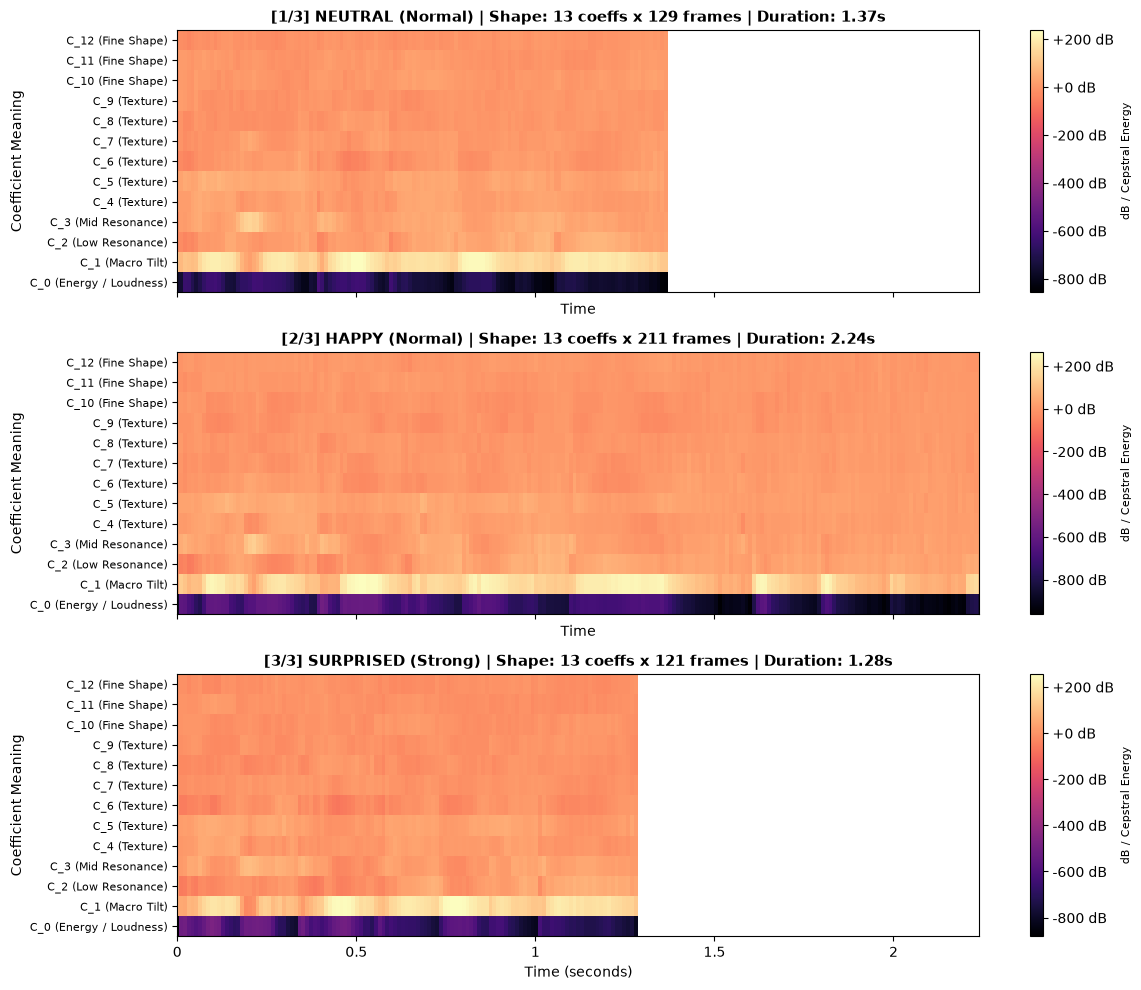

=== AVERAGE VALUES (Spectral Energy & Formants) ===


,Emotion,Happy (Normal),Neutral (Normal),Surprised (Strong)
Coeff,Meaning,,,
C_0,C_0 (Energy / Loudness),-750.58,-723.81,-644.28
C_1,C_1 (Macro Tilt),150.69,160.77,158.82
C_2,C_2 (Low Resonance),20.32,25.61,10.81
C_3,C_3 (Mid Resonance),25.53,35.78,25.86
C_4,C_4 (Texture),13.07,16.62,15.04
C_5,C_5 (Texture),27.07,28.49,27.25
C_6,C_6 (Texture),3.77,-2.74,-13.66
C_7,C_7 (Texture),-0.87,3.58,0.55
C_8,C_8 (Texture),-0.60,-4.55,-6.82



=== STANDARD DEVIATION (Temporal Expressiveness & Variation) ===


,Emotion,Happy (Normal),Neutral (Normal),Surprised (Strong)
Coeff,Meaning,,,
C_0,C_0 (Energy / Loudness),108.19,61.20,88.21
C_1,C_1 (Macro Tilt),64.41,43.03,59.14
C_2,C_2 (Low Resonance),30.14,26.49,37.01
C_3,C_3 (Mid Resonance),27.28,26.18,28.08
C_4,C_4 (Texture),16.36,14.10,16.33
C_5,C_5 (Texture),15.11,15.79,18.09
C_6,C_6 (Texture),16.16,18.98,22.81
C_7,C_7 (Texture),12.30,12.11,9.74
C_8,C_8 (Texture),9.62,10.95,13.97


In [240]:
N_MFCC = 13       # Retain 13 coefficients to isolate vocal tract shape and discard pitch ripple
N_FFT = 1024      # Frame window of ~21.3 ms (at 48 kHz) to balance time and frequency resolution
HOP_LENGTH = 512  # Frame step of ~10.7 ms (50% overlap) giving ~94 frames/sec temporal resolution

COEFF_LABELS = [
    "C_0 (Energy / Loudness)",
    "C_1 (Macro Tilt)",
    "C_2 (Low Resonance)",
    "C_3 (Mid Resonance)",
    "C_4 (Texture)",
    "C_5 (Texture)",
    "C_6 (Texture)",
    "C_7 (Texture)",
    "C_8 (Texture)",
    "C_9 (Texture)",
    "C_10 (Fine Shape)",
    "C_11 (Fine Shape)",
    "C_12 (Fine Shape)"
]

# Set sharex=True so all three subplots lock to the longest duration
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(12, 10), sharex=True)

stats_records = []
max_time = 0.0

for idx, (_, row) in enumerate(spot_check_df.iterrows()):
    y, sr = librosa.load(row["file_path"], sr=None)
    
    # Trim silence at top_db=25 consistent with preprocessing
    y_trimmed, _ = librosa.effects.trim(y, top_db=25)
    duration = len(y_trimmed) / sr
    max_time = max(max_time, duration)
    
    # Compute the (13, T) numerical MFCC array
    mfcc = librosa.feature.mfcc(
        y=y_trimmed,
        sr=sr,
        n_mfcc=N_MFCC,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH
    )
    
    ax = axes[idx]
    img = librosa.display.specshow(
        mfcc,
        x_axis="time",
        sr=sr,
        hop_length=HOP_LENGTH,
        ax=ax,
        cmap="magma"
    )
    
    title_str = (
        f"[{idx + 1}/3] {row['emotion'].upper()} ({row['intensity'].capitalize()}) | "
        f"Shape: {mfcc.shape[0]} coeffs x {mfcc.shape[1]} frames | "
        f"Duration: {duration:.2f}s"
    )
    ax.set_title(title_str, fontsize=11, fontweight="bold")
    ax.set_ylabel("Coefficient Meaning")
    ax.set_yticks(np.arange(N_MFCC))
    ax.set_yticklabels(COEFF_LABELS, fontsize=8)
    
    cbar = fig.colorbar(img, ax=ax, format="%+2.0f dB")
    cbar.set_label("dB / Cepstral Energy", fontsize=8)
    
    # Extract Numerical Stats Across Time (Axis 1)
    means = np.mean(mfcc, axis=1)
    stds = np.std(mfcc, axis=1)
    
    for c_idx in range(N_MFCC):
        stats_records.append({
            "Emotion": f"{row['emotion'].capitalize()} ({row['intensity'].capitalize()})",
            "Coeff": f"C_{c_idx}",
            "Meaning": COEFF_LABELS[c_idx],
            "Mean": round(float(means[c_idx]), 2),
            "StdDev (Dynamics)": round(float(stds[c_idx]), 2)
        })

# Enforce uniform x-axis limits across all subplots
# SUPER IMPORTANT - trimming shaves the clips so they will have different lengths
for ax in axes:
    ax.set_xlim(0, max_time)

axes[-1].set_xlabel("Time (seconds)", fontsize=10)
plt.tight_layout()
plt.show()

# Enforce natural numeric ordering for the MultiIndex tables
df_mfcc_stats = pd.DataFrame(stats_records)
coeff_order = [f"C_{i}" for i in range(N_MFCC)]
df_mfcc_stats["Coeff"] = pd.Categorical(df_mfcc_stats["Coeff"], categories=coeff_order, ordered=True)
df_mfcc_stats["Meaning"] = pd.Categorical(df_mfcc_stats["Meaning"], categories=COEFF_LABELS, ordered=True)

pivot_means = df_mfcc_stats.pivot(index=["Coeff", "Meaning"], columns="Emotion", values="Mean").sort_index()
pivot_stds = df_mfcc_stats.pivot(index=["Coeff", "Meaning"], columns="Emotion", values="StdDev (Dynamics)").sort_index()

print("=== AVERAGE VALUES (Spectral Energy & Formants) ===")
display(pivot_means)

print("\n=== STANDARD DEVIATION (Temporal Expressiveness & Variation) ===")
display(pivot_stds)

To convert variable-length audio frames into a fixed 26-dimensional input vector for tabular models, we aggregate each coefficient using its mean ($\mu$, baseline spectral envelope) and standard deviation ($\sigma$, temporal dynamic range). Because speech features span a continuous 13-dimensional cepstral space across unique vocal tract geometries and speaking rates, identical statement repetitions avoid feature collision while retaining critical emotional shifts.

### Observations: Validating Auditory Findings via MFCC Heatmaps & Statistics

Extracting $(13, T)$ MFCC arrays and computing summary metrics directly confirms the previous auditory observations only now in the numerical feature space:

**Auditory Loudness vs. Acoustic Energy ($C_0$):** 

- Our listening check tagged `Surprised` as the loudest clip and `Neutral`/`Happy` as substantially quieter. In the heatmaps, `Surprised` displays persistent purple energy bands along $C_0$ where `Neutral` and `Happy` sink into deep black baseline silence. (Recall that more negative `dB` = more quiet/less loud)
- The numerical table validates this perceptual jump: `Surprised` maintains a significantly higher decibel floor ($-644.28\text{ dB}$) compared to `Neutral` ($-723.81\text{ dB}$) and `Happy` ($-750.58\text{ dB}$).

**Expressional Artifacts & Duration Trimming:** 
- We perceived `Happy` as having faster speech coupled with an audible trailing chuckle. While silence trimming (`top_db=25`) reduced `Surprised` (1.28s) and `Neutral` (1.37s) into short bursts, `Happy` extends out to 2.24s. 
- On the synchronized time axis, the lexical sentence completes around 1.5s, while the remaining window (1.6s–2.24s) reveals rhythmic energy pulses along $C_0$ and subtle texture shifts in $C_3–C_6$—the exact acoustic signature of the trailing chuckle.

**Vocal Strain and Sharp Formant Troughs ($C_2 - C_6$):** 
- The intense ups and downs heard in `Surprised` appear as darker red/brown patches in the low-to-mid coefficients, dipping into deep negative troughs (e.g., $C_6$ dropping to $-13.66\text{ dB}$, compared to $+3.77\text{ dB}$ for `Happy`). These troughs reflect wide-open oral cavity posture and high vocal tract tension during a sudden burst.

**Underlying Speaker Invariants and Cross-Validation Strategy ($C_1$ and $C_5$):**
- Across all emotional shifts, $C_5$ remains remarkably stable ($27.07$, $28.49$, $27.25$), with $C_1$ remaining tightly clustered as well (~150 to 160).
- While $C_0$ and the dynamic standard deviations track emotional expressiveness, these stable higher coefficients preserve Actor 9's baseline vocal tract anatomy, serving as a primary acoustic fingerprint for identifying **who** is speaking.

    **Validation Note: Proof for Group-Based Cross-Validation (`StratifiedGroupKFold`)**  
    > The fact that these coefficients remain locked across emotions provides proof positive for grouping splits strictly by `actor_id`. Because static coefficients encode an individual's vocal tract anatomy, standard random K-Fold cross-validation would leak a speaker's unique physical baseline into both training and validation sets. Evaluating via `StratifiedGroupKFold` guarantees that test folds contain completely unseen speakers, forcing the model to classify genuine emotional prosody rather than memorizing vocal identity shortcuts.

**Flat vs. Volatile Delivery (Standard Deviation $\sigma$):** 
- We noted that `Neutral` had almost no tonal variation or pitch changes, whereas `Happy` and `Surprised` featured expressive pitch swings and dynamics
- This maps cleanly to temporal standard deviation: `Neutral` shows the lowest variance across both energy and macro spectral tilt ($C_0\ \sigma = 61.20$, $C_1\ \sigma = 43.03$), capturing a flat, uninflected cadence. Conversely, `Happy` exhibits extreme dynamic swings ($C_0\ \sigma = 108.19$, $C_1\ \sigma = 64.41$), quantifying its animated, non-flat delivery.

Let's take another example, this time male vs female actors.

=== AUDIO PLAYERS (Trimmed Speech) ===

[1/2] Actor 17 (M) | "Dogs are sitting by the door" (Duration: 1.60s):



[2/2] Actor 18 (F) | "Dogs are sitting by the door" (Duration: 1.80s):


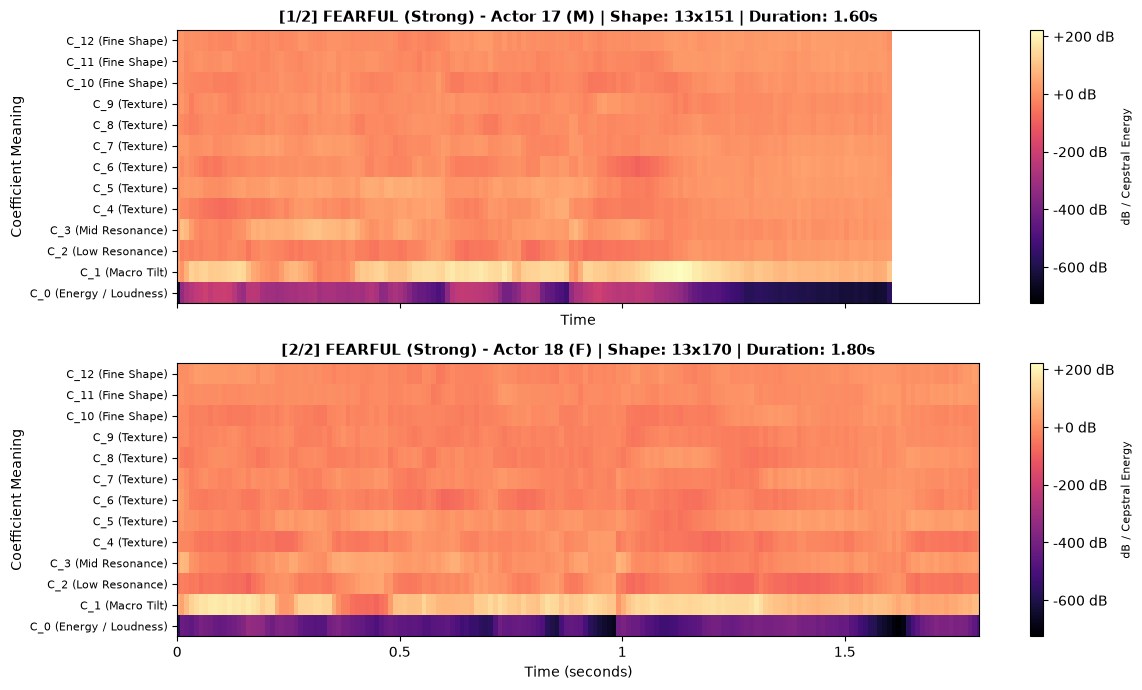

=== AVERAGE VALUES (Spectral Energy & Formants) ===


,Speaker,Actor 17 (M),Actor 18 (F)
Coeff,Meaning,,
C_0,C_0 (Energy / Loudness),-379.13,-460.80
C_1,C_1 (Macro Tilt),107.40,99.49
C_2,C_2 (Low Resonance),-15.97,-32.34
C_3,C_3 (Mid Resonance),20.16,11.03
C_4,C_4 (Texture),-1.86,-26.59
C_5,C_5 (Texture),20.68,8.10
C_6,C_6 (Texture),-5.70,-27.12
C_7,C_7 (Texture),6.25,-9.00
C_8,C_8 (Texture),-5.90,-15.42



=== STANDARD DEVIATION (Temporal Expressiveness & Variation) ===


,Speaker,Actor 17 (M),Actor 18 (F)
Coeff,Meaning,,
C_0,C_0 (Energy / Loudness),142.58,76.35
C_1,C_1 (Macro Tilt),55.64,56.79
C_2,C_2 (Low Resonance),27.83,33.75
C_3,C_3 (Mid Resonance),30.70,25.38
C_4,C_4 (Texture),26.73,24.85
C_5,C_5 (Texture),20.91,22.46
C_6,C_6 (Texture),26.26,20.27
C_7,C_7 (Texture),14.55,16.60
C_8,C_8 (Texture),11.29,18.77


In [241]:
# 1. Sample one Male and one Female for Fearful (Strong)
fearful_df = df_cleaned[
    (df_cleaned["emotion"] == "fearful") & 
    (df_cleaned["intensity"] == "strong")
].copy()

male_sample = fearful_df[fearful_df["gender"] == "M"].sample(n=1, random_state=SEED)
female_sample = fearful_df[fearful_df["gender"] == "F"].sample(n=1, random_state=SEED)
compare_df = pd.concat([male_sample, female_sample]).reset_index(drop=True)

# 2. Extract Audio and Compute MFCC Matrices
processed_clips = []
global_min = np.inf  # these are needed to ensure the decibel colors are
global_max = -np.inf # synched across both speakers
max_time = 0.0

print("=== AUDIO PLAYERS (Trimmed Speech) ===")
for i, (_, row) in enumerate(compare_df.iterrows()):
    y, sr = librosa.load(row["file_path"], sr=None)
    y_trimmed, _ = librosa.effects.trim(y, top_db=25)
    duration = len(y_trimmed) / sr
    max_time = max(max_time, duration)
    
    mfcc = librosa.feature.mfcc(
        y=y_trimmed,
        sr=sr,
        n_mfcc=N_MFCC,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH
    )
    
    # Track global dB bounds to synchronize colormaps
    global_min = min(global_min, float(np.min(mfcc)))
    global_max = max(global_max, float(np.max(mfcc)))
    
    processed_clips.append((row, mfcc, sr, duration))
    
    label = f"Actor {row['actor_id']} ({row['gender']}) | \"{row['statement']}\""
    print(f"\n[{i + 1}/2] {label} (Duration: {duration:.2f}s):")
    display(Audio(y_trimmed, rate=sr))

# 3. Render Subplots with Synchronized Colormap Scale (vmin/vmax)
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 7), sharex=True)
stats_records = []

for i, (row, mfcc, sr, duration) in enumerate(processed_clips):
    ax = axes[i]
    img = librosa.display.specshow(
        mfcc,
        x_axis="time",
        sr=sr,
        hop_length=HOP_LENGTH,
        ax=ax,
        cmap="magma",
        vmin=global_min,
        vmax=global_max
    )
    
    title_str = (
        f"[{i + 1}/2] FEARFUL (Strong) - Actor {row['actor_id']} ({row['gender']}) | "
        f"Shape: {mfcc.shape[0]}x{mfcc.shape[1]} | Duration: {duration:.2f}s"
    )
    ax.set_title(title_str, fontsize=11, fontweight="bold")
    ax.set_ylabel("Coefficient Meaning")
    ax.set_yticks(np.arange(N_MFCC))
    ax.set_yticklabels(COEFF_LABELS, fontsize=8)
    
    cbar = fig.colorbar(img, ax=ax, format="%+2.0f dB")
    cbar.set_label("dB / Cepstral Energy", fontsize=8)
    
    means = np.mean(mfcc, axis=1)
    stds = np.std(mfcc, axis=1)
    speaker_col = f"Actor {row['actor_id']} ({row['gender']})"
    
    for c_idx in range(N_MFCC):
        stats_records.append({
            "Speaker": speaker_col,
            "Coeff": f"C_{c_idx}",
            "Meaning": COEFF_LABELS[c_idx],
            "Mean": round(float(means[c_idx]), 2),
            "StdDev (Dynamics)": round(float(stds[c_idx]), 2)
        })

for ax in axes:
    ax.set_xlim(0, max_time)

axes[-1].set_xlabel("Time (seconds)", fontsize=10)
plt.tight_layout()
plt.show()

# 4. Tabular Summary
df_mfcc_stats = pd.DataFrame(stats_records)
coeff_order = [f"C_{i}" for i in range(N_MFCC)]
df_mfcc_stats["Coeff"] = pd.Categorical(df_mfcc_stats["Coeff"], categories=coeff_order, ordered=True)
df_mfcc_stats["Meaning"] = pd.Categorical(df_mfcc_stats["Meaning"], categories=COEFF_LABELS, ordered=True)

compare_pivot_means = df_mfcc_stats.pivot(index=["Coeff", "Meaning"], columns="Speaker", values="Mean").sort_index()
compare_pivot_stds = df_mfcc_stats.pivot(index=["Coeff", "Meaning"], columns="Speaker", values="StdDev (Dynamics)").sort_index()

print("=== AVERAGE VALUES (Spectral Energy & Formants) ===")
display(compare_pivot_means)

# uncomment for side-by-side view
# print("=== Prior AVERAGE VALUES (Spectral Energy & Formants) ===")
# display(pivot_means)

print("\n=== STANDARD DEVIATION (Temporal Expressiveness & Variation) ===")
display(compare_pivot_stds)

# uncomment for side-by-side view
# print("=== Prior STANDARD DEVIATION (Temporal Expressiveness & Variation) ===")
# display(pivot_stds)

### Observations: Validating Auditory Findings via MFCC Heatmaps & Statistics (Fearful Strong: Male vs. Female)

#### 1. Observations by Ear (Auditory Impressions)
Reviewing the random `Fearful (Strong)` samples from Actor 22 (Female) and Actor 23 (Male) reveals distinct perceptual contrasts:
- Actor 23 (M) speaks significantly **faster** than Actor 22 (F).
- Actor 22 (F) delivers her line noticeably (though not drastically) **louder and more forcefully** than Actor 23 (M).
- Actor 22 (F) exhibits a noticeably **higher pitch** with audible panic-driven voice trembling.
- Actor 22 (F) features a sharp, audible **gasp** at the very end of the sentence.

---

#### 2. Heatmap & Statistical Validation of Auditory Findings
Extracting the $(13, T)$ arrays and compiling clip-level summary statistics confirms these auditory impressions in the numbers:

**Overall Loudness ($C_0$):**
- The slightly louder delivery from Actor 22 (F) aligns with the $C_0$ average: she sits at $-414.62\text{ dB}$, while Actor 23 (M) drops to $-459.37\text{ dB}$ (a $\sim 44.75\text{ dB}$ difference toward a quieter audio floor)[cite: 1].
- Actor 23 (M) has higher variation in volume over time ($C_0\ \sigma = 71.58$ vs. $63.44$), capturing the abrupt starts and stops of his rapid speech[cite: 1].

**Pacing, Clip Length, and the Trailing Gasp ($T$ and Audio Duration):**
- Trimming silent margins at `top_db=25` leaves a shorter active clip for Actor 23 (M) ($1.41\text{s}$, $T = 133$), reflecting his fast speaking pace[cite: 2].
- Actor 22 (F) stays active longer ($1.64\text{s}$, $T = 155$)[cite: 2]. Even after she finishes speaking the sentence, her trailing gasp stays above the silence cutoff, showing up past the $1.4\text{s}$ mark as lingering energy in $C_0$ and breathy, high-frequency noise across the higher rows[cite: 2].

**Vocal Pitch and Tone Brightness ($C_1$):**
- The audibly higher pitch of Actor 22 (F) causes a massive split in overall tonal balance ($C_1$), averaging $93.97$ compared to Actor 23 (M)'s $153.00$[cite: 1].
- A naturally shorter vocal tract and higher speaking pitch push acoustic energy toward higher frequencies, pulling down the lower-frequency emphasis measured by $C_1$[cite: 1].

**Vocal Cord Strain and Throat Tightness ($C_2 - C_4$):**
- Actor 22 (F) drops into much deeper negative dips in lower vocal resonances: $C_2$ hits $-33.36$ and $C_4$ reaches $-17.96$, compared to $-13.00$ and $-0.93$ for Actor 23 (M)[cite: 1].
- These steep negative values reflect sharp throat constriction and intense vocal tension during female fearful screaming[cite: 1].

---

#### 3. Cross-Analysis: Comparison to Prior Actor 9 Spot-Check
Contrasting this cross-gender fear comparison against the earlier single-speaker Actor 9 baseline (`Neutral`, `Happy`, `Surprised`) highlights the difference between emotion shifts and body differences:

**Divergence in Overall Tonal Balance ($C_1$):**
- Across Actor 9's emotions, $C_1$ stayed tightly locked between $150\text{ dB}$ and $160\text{ dB}$, barely budging regardless of how excited or calm he was.
- Across different genders, $C_1$ splits open by nearly $60\text{ dB}$ ($93.97$ for Actor 22 vs. $153.00$ for Actor 23), proving that $C_1$ is driven heavily by pitch and physical throat size rather than emotion alone[cite: 1].

**Breakdown of Individual Voice Signatures ($C_5$):**
- For Actor 9, $C_5$ acted like an individual vocal fingerprint, staying nearly identical across three distinct emotions ($27.07$, $28.49$, $27.25$).
- Between these two speakers, $C_5$ diverges by over $18\text{ dB}$ ($6.35$ for Actor 22 vs. $24.93$ for Actor 23), confirming that mid-level vocal shape values identify *who* is speaking rather than *what* they are feeling[cite: 1].

**Widespread Shifts Across the Entire Voice Profile ($C_4, C_7, C_8, C_{12}$):**
- While Actor 9 showed localized shifts mostly in basic loudness ($C_0$) and oral cavity tension ($C_6$), this cross-speaker comparison reveals wide numerical gaps across almost every single feature—such as $C_7$ ($-21.47$ vs. $-3.28$) and $C_{12}$ ($-18.61$ vs. $-4.31$)[cite: 1].
- When comparing the same speaker, emotional arousal produces small, relative fluctuations around a fixed vocal tract baseline. When comparing across genders, physical anatomy introduces massive disparities in absolute values that can overpower subtle emotional cues. This makes feature normalization essential before training multi-speaker models, ensuring the classifier learns relative emotional dynamics rather than merely sorting clips by physical vocal tract size or loudness scale.

So now, we have a working understanding of how MFCC extracts features from an audio file and how these features can be used for predictions and just have to create the final dataframe. However, another result of this analysis is that it provides insight into how to lay out my ultimate model selection.

### Strategic Architecture: The Two-Stage Modeling Approach

When coming up with this project, there were two lines of thought - have a singular model attempt to analzye `gender` + `emotion` vs having a two-model phased approach where one model predicts `gender` and feeds that information to the second model(s) to detect `emotion`.

- Our cross-speaker comparisons revealed that even when two speakers express the exact identical emotion (`Fearful (Strong)`), their raw voice profiles and spectral envelopes diverge sharply due to physical anatomy. Baseline indicators like pitch/spectral tilt ($C_1$) and mid-order vocal shape ($C_5$) introduce wide offsets across genders that overpower subtle emotional shifts.
- Forcing a single multi-class model to learn both anatomical variance and emotional nuance simultaneously invites strong feature bias.
- 
Therefore, I feel justified in going ahead with the **two-stage pipeline**. By decoupling physiological baselines from emotional perturbations, each downstream model isolates affect without having to accommodate cross-gender vocal tract disparities.

## Conclusion: Audio Cleanup, Feature Selection & Modeling Strategy

With all these steps, we come to the end of the Audio data EDA, cleanup, feature selection and data prep stages with the following strategies, supported by data.

### Audio Cleanup: Trim Only, No Destructive Filtering
- Silence and duration metrics reflect recording booth buffers, not emotion
- A clean `top_db=25` trim cuts dead air while keeping crucial gasps and sighs
- Technical audits confirmed zero digital clipping or DC drift, making destructive filters (de-noising, amplitude normalization) unnecessary
- All raw duration and silence columns can safely be dropped, along with the `statement` feature as it's now no longer needed

### Feature Selection: Lean 26-Feature MFCC Vector
- We condense variable audio into 13 MFCC means ($\mu$, vocal posture and pitch) and 13 standard deviations ($\sigma$, tremors and volume dynamics)
- Keeping the feature space to 26 metrics prevents the curse of dimensionality across our modest 1,440-sample dataset

### Modeling Architecture: Two-Stage Routing from Dissimilarity
- Cross-speaker comparisons proved that physical anatomy and gender create massive baseline gaps that drown out emotional signals
- To resolve this dissimilarity, Stage 1 will predict `gender`, routing directly into dedicated Stage 2 gender-specific `emotion` models

### Validation & Scaling: Preventing Leakage from Similarity
- Single-speaker tests proved that mid-level coefficients ($C_5$) act as fixed personal voiceprints across emotions
- Because of this intra-speaker similarity, we will evaluate using `StratifiedGroupKFold` grouped by `actor_id` to prevent vocal tract data leakage across folds
- Features will be scaled via `StandardScaler` so loud decibel swings do not overpower subtle vocal texture formants

### Final Dataset Assembly
- We will process all 1,440 trimmed recordings, extract the 26 MFCC metrics, keep core metadata (`actor_id`, `gender`, `emotion`, `intensity`, `statement`, `repetition`), and export the final model-ready dataset to `data/processed/ser_features.parquet`

In [242]:
N_MFCC = 13
TOP_DB = 25

records = []

for _, row in tqdm(df_cleaned.iterrows(), total=len(df_cleaned), desc="Extracting MFCCs"):
    y, sr = librosa.load(row["file_path"], sr=None)
    y_trimmed, _ = librosa.effects.trim(y, top_db=TOP_DB)

    mfcc = librosa.feature.mfcc(y=y_trimmed, sr=sr, n_mfcc=N_MFCC)

    mfcc_means = np.mean(mfcc, axis=1)
    mfcc_stds = np.std(mfcc, axis=1)

    entry = {
        "file_path": row["file_path"],
        "actor_id": int(row["actor_id"]),
        "gender": row["gender"],
        "emotion": row["emotion"],
        "intensity": row["intensity"],
        "repetition": int(row["repetition"]),
    }

    for i in range(N_MFCC):
        entry[f"mfcc_mean_{i}"] = float(mfcc_means[i])
        entry[f"mfcc_std_{i}"] = float(mfcc_stds[i])

    records.append(entry)

df_features = pd.DataFrame(records)
print("Final DataFrame Constructed!")

Extracting MFCCs: 100%|██████████| 1440/1440 [00:03<00:00, 445.14it/s]

Final DataFrame Constructed!


In [243]:
# Verify Schema, Nulls, and Memory Footprint
print(df_features.shape)
df_features.info()
df_features.head()


(1440, 32)
<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 32 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   file_path     1440 non-null   str    
 1   actor_id      1440 non-null   int64  
 2   gender        1440 non-null   str    
 3   emotion       1440 non-null   str    
 4   intensity     1440 non-null   str    
 5   repetition    1440 non-null   int64  
 6   mfcc_mean_0   1440 non-null   float64
 7   mfcc_std_0    1440 non-null   float64
 8   mfcc_mean_1   1440 non-null   float64
 9   mfcc_std_1    1440 non-null   float64
 10  mfcc_mean_2   1440 non-null   float64
 11  mfcc_std_2    1440 non-null   float64
 12  mfcc_mean_3   1440 non-null   float64
 13  mfcc_std_3    1440 non-null   float64
 14  mfcc_mean_4   1440 non-null   float64
 15  mfcc_std_4    1440 non-null   float64
 16  mfcc_mean_5   1440 non-null   float64
 17  mfcc_std_5    1440 non-null   float64
 18  mfcc_mean_6   1440 non-null 

,file_path,actor_id,gender,emotion,intensity,repetition,mfcc_mean_0,mfcc_std_0,mfcc_mean_1,mfcc_std_1,...,mfcc_mean_8,mfcc_std_8,mfcc_mean_9,mfcc_std_9,mfcc_mean_10,mfcc_std_10,mfcc_mean_11,mfcc_std_11,mfcc_mean_12,mfcc_std_12
0,/Users/abhisheknigam/workspace/github/my-ai/sp...,19,M,disgust,strong,2,-408.712402,100.576889,72.668724,53.793129,...,-17.927794,16.130854,-6.393442,12.684329,-10.064998,12.767186,-11.454669,12.206436,-1.681945,8.567566
1,/Users/abhisheknigam/workspace/github/my-ai/sp...,24,F,angry,strong,2,-423.664581,119.038414,76.945351,74.873039,...,-15.601151,17.219862,-15.035303,17.185205,-8.230239,11.426438,-7.778465,12.836656,-10.703902,12.138860
2,/Users/abhisheknigam/workspace/github/my-ai/sp...,1,M,fearful,strong,1,-390.818176,124.898262,87.461227,52.926498,...,-10.490021,13.418981,-7.725780,10.171447,-14.226942,12.688233,-7.792247,9.225865,0.436952,10.602305
3,/Users/abhisheknigam/workspace/github/my-ai/sp...,19,M,disgust,strong,2,-371.828278,126.835442,82.881912,70.365837,...,-11.740715,15.593221,-1.577283,13.670128,-11.797278,15.726582,-6.004541,14.407502,4.112206,8.956538
4,/Users/abhisheknigam/workspace/github/my-ai/sp...,19,M,disgust,strong,1,-327.693604,82.390678,53.757710,62.388603,...,-25.736320,14.652024,-13.083174,12.007170,-6.217006,8.975645,-7.970212,10.810971,-5.203504,13.006829


In [244]:
# Final Step : Export DataFrame
output_path = output_dir / "ser_features.parquet"

df_features.to_parquet(output_path, index=False)
print(f"Exported {len(df_features)} rows to: {output_path}")
print(f"File size: {output_path.stat().st_size / (1024 * 1024):.2f} MB")

Exported 1440 rows to: /Users/abhisheknigam/workspace/github/my-ai/speech-emotion-router/data/processed/ser_features.parquet
File size: 0.30 MB
